In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import math
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten, text_color

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## data-mixture

**Figure 1: Pretraining data mixture over training under our three-stage curriculum.** Dashed lines mark the stage switches at 30k and 70k steps. The share of web text falls from 62% to 40%, while code grows from 12% to 24% and math from 6% to 18%.

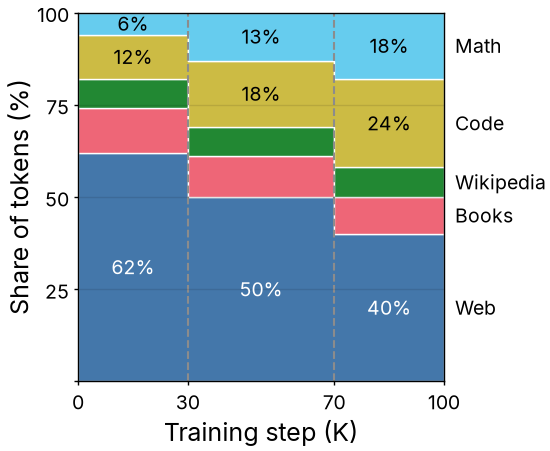

In [2]:
data = json.load(open("../data/data-mixture.json"))
steps = np.array(data["steps"]) / 1000
names = ["Web", "Books", "Wikipedia", "Code", "Math"]
shares = np.array([data["shares"][name] for name in names]) * 100
band_colors = [colors[f"series-{i + 1}"] for i in range(len(names))]
switches = [30, 70]

fig, ax = plt.subplots(figsize=(2.75, 2.75))
ax.stackplot(steps, shares, colors=band_colors, labels=names, step="post", edgecolor="white", linewidth=0.5)
for step in switches:
    ax.axvline(step, linestyle="--", linewidth=paper.dashed_width, color=colors["neutral"])

bottoms = np.vstack([np.zeros(len(steps)), np.cumsum(shares, axis=0)[:-1]])
stage_mids = [15, 50, 85]
for name in ["Web", "Code", "Math"]:
    i = names.index(name)
    for mid in stage_mids:
        k = np.searchsorted(steps, mid)
        ax.text(mid, bottoms[i, k] + shares[i, k] / 2, f"{shares[i, k]:.0f}%",
                ha="center", va="center", color=text_color(band_colors[i]))

for i, name in enumerate(names):
    ax.annotate(name, (1, bottoms[i, -1] + shares[i, -1] / 2), xycoords=("axes fraction", "data"),
                xytext=(4, 0), textcoords="offset points", va="center")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.margins(x=0)
ax.set_xticks([0, *switches, 100])
ax.set_yticks([0, 25, 50, 75, 100], labels=["", "25", "50", "75", "100"])
ax.set_axisbelow(False)
ax.grid(axis="x", visible=False)
ax.set_xlabel("Training step (K)")
ax.set_ylabel("Share of tokens (%)")

fit_height(fig, ax, aspect=1.0)
fig.savefig("../outputs/data-mixture.pdf")
fig.savefig("../outputs/data-mixture.png")
plt.show()